In [214]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import OrdinalEncoder

In [102]:
df=pd.read_csv("C:/Users/Laveena/OneDrive/Desktop/Retail_Demand_Forecasting/data/train.csv")

In [103]:
df.head()

,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0


In [104]:
df.shape

(3000888, 6)

In [105]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000888 entries, 0 to 3000887
Data columns (total 6 columns):
 #   Column       Dtype  
---  ------       -----  
 0   id           int64  
 1   date         object 
 2   store_nbr    int64  
 3   family       object 
 4   sales        float64
 5   onpromotion  int64  
dtypes: float64(1), int64(3), object(2)
memory usage: 137.4+ MB


In [106]:
df.describe()

,id,store_nbr,sales,onpromotion
count,3.000888e+06,3.000888e+06,3.000888e+06,3.000888e+06
mean,1.500444e+06,2.750000e+01,3.577757e+02,2.602770e+00
std,8.662819e+05,1.558579e+01,1.101998e+03,1.221888e+01
min,0.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00
25%,7.502218e+05,1.400000e+01,0.000000e+00,0.000000e+00
50%,1.500444e+06,2.750000e+01,1.100000e+01,0.000000e+00
75%,2.250665e+06,4.100000e+01,1.958473e+02,0.000000e+00
max,3.000887e+06,5.400000e+01,1.247170e+05,7.410000e+02


In [107]:
df.isnull().sum()

id             0
date           0
store_nbr      0
family         0
sales          0
onpromotion    0
dtype: int64

In [108]:
df.duplicated().sum()

np.int64(0)

In [109]:
df['family'].nunique()

33

In [110]:
df['store_nbr'].nunique()

54

In [111]:
df['date'].min(),df['date'].max()

('2013-01-01', '2017-08-15')

In [112]:
stores=pd.read_csv("C:/Users/Laveena/OneDrive/Desktop/Retail_Demand_Forecasting/data/stores.csv")

In [113]:
stores.head()

,store_nbr,city,state,type,cluster
0,1,Quito,Pichincha,D,13
1,2,Quito,Pichincha,D,13
2,3,Quito,Pichincha,D,8
3,4,Quito,Pichincha,D,9
4,5,Santo Domingo,Santo Domingo de los Tsachilas,D,4


In [114]:
stores.shape

(54, 5)

In [115]:
stores.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54 entries, 0 to 53
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   store_nbr  54 non-null     int64 
 1   city       54 non-null     object
 2   state      54 non-null     object
 3   type       54 non-null     object
 4   cluster    54 non-null     int64 
dtypes: int64(2), object(3)
memory usage: 2.2+ KB


In [116]:
stores.isnull().sum()

store_nbr    0
city         0
state        0
type         0
cluster      0
dtype: int64

In [117]:
stores['city'].value_counts()

city
Quito            18
Guayaquil         8
Cuenca            3
Santo Domingo     3
Manta             2
Latacunga         2
Machala           2
Ambato            2
Quevedo           1
Esmeraldas        1
Loja              1
Libertad          1
Playas            1
Daule             1
Babahoyo          1
Salinas           1
Puyo              1
Guaranda          1
Ibarra            1
Riobamba          1
Cayambe           1
El Carmen         1
Name: count, dtype: int64

In [118]:
stores['state'].nunique()

16

In [119]:
stores['type'].value_counts()

type
D    18
C    15
A     9
B     8
E     4
Name: count, dtype: int64

In [120]:
stores['cluster'].value_counts()

cluster
3     7
6     6
10    6
15    5
13    4
14    4
11    3
4     3
8     3
1     3
9     2
7     2
2     2
12    1
5     1
16    1
17    1
Name: count, dtype: int64

In [121]:
oil=pd.read_csv("C:/Users/Laveena/OneDrive/Desktop/Retail_Demand_Forecasting/data/oil.csv")

In [122]:
oil.head()

,date,dcoilwtico
0,2013-01-01,NaN
1,2013-01-02,93.14
2,2013-01-03,92.97
3,2013-01-04,93.12
4,2013-01-07,93.20


In [123]:
oil.shape

(1218, 2)

In [124]:
oil.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1218 entries, 0 to 1217
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   date        1218 non-null   object 
 1   dcoilwtico  1175 non-null   float64
dtypes: float64(1), object(1)
memory usage: 19.2+ KB


In [125]:
oil.isnull().sum()

date           0
dcoilwtico    43
dtype: int64

In [126]:
oil.describe()

,dcoilwtico
count,1175.000000
mean,67.714366
std,25.630476
min,26.190000
25%,46.405000
50%,53.190000
75%,95.660000
max,110.620000


In [127]:
holidays=pd.read_csv("C:/Users/Laveena/OneDrive/Desktop/Retail_Demand_Forecasting/data/holidays_events.csv")

In [128]:
holidays.head()

,date,type,locale,locale_name,description,transferred
0,2012-03-02,Holiday,Local,Manta,Fundacion de Manta,False
1,2012-04-01,Holiday,Regional,Cotopaxi,Provincializacion de Cotopaxi,False
2,2012-04-12,Holiday,Local,Cuenca,Fundacion de Cuenca,False
3,2012-04-14,Holiday,Local,Libertad,Cantonizacion de Libertad,False
4,2012-04-21,Holiday,Local,Riobamba,Cantonizacion de Riobamba,False


In [129]:
holidays.shape

(350, 6)

In [130]:
holidays.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 350 entries, 0 to 349
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   date         350 non-null    object
 1   type         350 non-null    object
 2   locale       350 non-null    object
 3   locale_name  350 non-null    object
 4   description  350 non-null    object
 5   transferred  350 non-null    bool  
dtypes: bool(1), object(5)
memory usage: 14.1+ KB


In [131]:
holidays.isnull().sum()

date           0
type           0
locale         0
locale_name    0
description    0
transferred    0
dtype: int64

In [132]:
holidays['type'].value_counts()

type
Holiday       221
Event          56
Additional     51
Transfer       12
Bridge          5
Work Day        5
Name: count, dtype: int64

In [133]:
holidays['description'].nunique()

103

In [134]:
holidays['transferred'].value_counts()

transferred
False    338
True      12
Name: count, dtype: int64

In [135]:
transaction=pd.read_csv("C:/Users/Laveena/OneDrive/Desktop/Retail_Demand_Forecasting/data/transactions.csv")

In [136]:
transaction.head()

,date,store_nbr,transactions
0,2013-01-01,25,770
1,2013-01-02,1,2111
2,2013-01-02,2,2358
3,2013-01-02,3,3487
4,2013-01-02,4,1922


In [137]:
transaction.shape

(83488, 3)

In [138]:
transaction.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 83488 entries, 0 to 83487
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   date          83488 non-null  object
 1   store_nbr     83488 non-null  int64 
 2   transactions  83488 non-null  int64 
dtypes: int64(2), object(1)
memory usage: 1.9+ MB


In [139]:
transaction.describe()

,store_nbr,transactions
count,83488.000000,83488.000000
mean,26.939237,1694.602158
std,15.608204,963.286644
min,1.000000,5.000000
25%,13.000000,1046.000000
50%,27.000000,1393.000000
75%,40.000000,2079.000000
max,54.000000,8359.000000


In [140]:
transaction['transactions'].mean()

np.float64(1694.6021583940208)

In [141]:
test=pd.read_csv("C:/Users/Laveena/OneDrive/Desktop/Retail_Demand_Forecasting/data/test.csv")

In [142]:
test.head()

,id,date,store_nbr,family,onpromotion
0,3000888,2017-08-16,1,AUTOMOTIVE,0
1,3000889,2017-08-16,1,BABY CARE,0
2,3000890,2017-08-16,1,BEAUTY,2
3,3000891,2017-08-16,1,BEVERAGES,20
4,3000892,2017-08-16,1,BOOKS,0


In [143]:
test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28512 entries, 0 to 28511
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   id           28512 non-null  int64 
 1   date         28512 non-null  object
 2   store_nbr    28512 non-null  int64 
 3   family       28512 non-null  object
 4   onpromotion  28512 non-null  int64 
dtypes: int64(3), object(2)
memory usage: 1.1+ MB


In [144]:
test.isnull().sum()

id             0
date           0
store_nbr      0
family         0
onpromotion    0
dtype: int64

In [145]:
test['store_nbr'].nunique()

54

In [146]:
test['family'].nunique()

33

In [147]:
sample=pd.read_csv("C:/Users/Laveena/OneDrive/Desktop/Retail_Demand_Forecasting/data/sample_submission.csv")

In [148]:
sample.head()

,id,sales
0,3000888,0.0
1,3000889,0.0
2,3000890,0.0
3,3000891,0.0
4,3000892,0.0


In [149]:
sample.shape

(28512, 2)

In [150]:
sample.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28512 entries, 0 to 28511
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   id      28512 non-null  int64  
 1   sales   28512 non-null  float64
dtypes: float64(1), int64(1)
memory usage: 445.6 KB


In [151]:
sample.isnull().sum()

id       0
sales    0
dtype: int64

In [152]:
sample.describe()

,id,sales
count,2.851200e+04,28512.0
mean,3.015144e+06,0.0
std,8.230850e+03,0.0
min,3.000888e+06,0.0
25%,3.008016e+06,0.0
50%,3.015144e+06,0.0
75%,3.022271e+06,0.0
max,3.029399e+06,0.0


## 2. Data Cleaning and Preprocessing

### 2.1 Date Conversion

In [153]:
df['date'] = pd.to_datetime(df['date'])
test['date'] = pd.to_datetime(test['date'])
oil['date'] = pd.to_datetime(oil['date'])
holidays['date'] = pd.to_datetime(holidays['date'])
transaction['date'] = pd.to_datetime(transaction['date'])

In [154]:
df['date'].dtypes

dtype('<M8[ns]')

In [155]:
print("Train:", df['date'].min(), "to", df['date'].max())
print("Test:", test['date'].min(), "to", test['date'].max())
print("Oil:", oil['date'].min(), "to", oil['date'].max())
print("Holidays:", holidays['date'].min(), "to", holidays['date'].max())
print("Transactions:", transaction['date'].min(), "to", transaction['date'].max())

Train: 2013-01-01 00:00:00 to 2017-08-15 00:00:00
Test: 2017-08-16 00:00:00 to 2017-08-31 00:00:00
Oil: 2013-01-01 00:00:00 to 2017-08-31 00:00:00
Holidays: 2012-03-02 00:00:00 to 2017-12-26 00:00:00
Transactions: 2013-01-01 00:00:00 to 2017-08-15 00:00:00


### 2.2 Missing Values

In [156]:
oil[oil['dcoilwtico'].isnull()].head(10)

,date,dcoilwtico
0,2013-01-01,NaN
14,2013-01-21,NaN
34,2013-02-18,NaN
63,2013-03-29,NaN
104,2013-05-27,NaN
132,2013-07-04,NaN
174,2013-09-02,NaN
237,2013-11-28,NaN
256,2013-12-25,NaN
261,2014-01-01,NaN


In [157]:
oil['dcoilwtico'].isnull().sum()

np.int64(43)

In [158]:
oil[oil['dcoilwtico'].isnull()]['date'].dt.day_name().value_counts()

date
Monday       23
Friday        9
Thursday      7
Tuesday       2
Wednesday     2
Name: count, dtype: int64

In [159]:
oil=oil.sort_values('date').copy()

In [160]:
oil['dcoilwtico']=oil['dcoilwtico'].ffill()

In [161]:
oil['dcoilwtico'].isnull().sum()

np.int64(1)

In [162]:
oil['dcoilwtico'] = oil['dcoilwtico'].bfill()

In [163]:
oil['dcoilwtico'].isnull().sum()

np.int64(0)

## 3. Dataset Merging
### 3.1 Merge Store Information

In [164]:
test=pd.merge(df,stores,on='store_nbr',how='left',validate='many_to_one')

In [165]:
test=pd.merge(df,stores,on='store_nbr',how='left',validate='many_to_one')

In [166]:
print("Training shape:", df.shape)
print("Testing shape:", test.shape)

print("\nTraining columns:")
print(df.columns.tolist())

print("\nTesting columns:")
print(test.columns.tolist())

Training shape: (3000888, 6)
Testing shape: (3000888, 10)

Training columns:
['id', 'date', 'store_nbr', 'family', 'sales', 'onpromotion']

Testing columns:
['id', 'date', 'store_nbr', 'family', 'sales', 'onpromotion', 'city', 'state', 'type', 'cluster']


In [167]:
# Reload original test dataset
test = pd.read_csv("C:/Users/Laveena/OneDrive/Desktop/Retail_Demand_Forecasting/data/test.csv")

# Convert date into datetime
test['date'] = pd.to_datetime(test['date'])

# Merge store information
test = pd.merge(
    test,
    stores,
    on='store_nbr',
    how='left',
    validate='many_to_one'
)

# Check results
print("Test shape:", test.shape)
print("Test columns:", test.columns.tolist())

display(test.head())

Test shape: (28512, 9)
Test columns: ['id', 'date', 'store_nbr', 'family', 'onpromotion', 'city', 'state', 'type', 'cluster']


,id,date,store_nbr,family,onpromotion,city,state,type,cluster
0,3000888,2017-08-16,1,AUTOMOTIVE,0,Quito,Pichincha,D,13
1,3000889,2017-08-16,1,BABY CARE,0,Quito,Pichincha,D,13
2,3000890,2017-08-16,1,BEAUTY,2,Quito,Pichincha,D,13
3,3000891,2017-08-16,1,BEVERAGES,20,Quito,Pichincha,D,13
4,3000892,2017-08-16,1,BOOKS,0,Quito,Pichincha,D,13


In [168]:
test.head()

,id,date,store_nbr,family,onpromotion,city,state,type,cluster
0,3000888,2017-08-16,1,AUTOMOTIVE,0,Quito,Pichincha,D,13
1,3000889,2017-08-16,1,BABY CARE,0,Quito,Pichincha,D,13
2,3000890,2017-08-16,1,BEAUTY,2,Quito,Pichincha,D,13
3,3000891,2017-08-16,1,BEVERAGES,20,Quito,Pichincha,D,13
4,3000892,2017-08-16,1,BOOKS,0,Quito,Pichincha,D,13


In [169]:
test.head()

,id,date,store_nbr,family,onpromotion,city,state,type,cluster
0,3000888,2017-08-16,1,AUTOMOTIVE,0,Quito,Pichincha,D,13
1,3000889,2017-08-16,1,BABY CARE,0,Quito,Pichincha,D,13
2,3000890,2017-08-16,1,BEAUTY,2,Quito,Pichincha,D,13
3,3000891,2017-08-16,1,BEVERAGES,20,Quito,Pichincha,D,13
4,3000892,2017-08-16,1,BOOKS,0,Quito,Pichincha,D,13


In [170]:
print("Training:", df.shape)
print("Testing:", test.shape)

Training: (3000888, 6)
Testing: (28512, 9)


In [171]:
df = pd.merge(
    df,
    oil[['date', 'dcoilwtico']],
    on='date',
    how='left',
    validate='many_to_one'
)

In [172]:
test = pd.merge(
    test,
    oil[['date', 'dcoilwtico']],
    on='date',
    how='left',
    validate='many_to_one'
)

In [173]:
print("Training shape:", df.shape)
print("Testing shape:", test.shape)

print("Training missing oil prices:",
      df['dcoilwtico'].isnull().sum())

print("Testing missing oil prices:",
      test['dcoilwtico'].isnull().sum())

display(df.head())

Training shape: (3000888, 7)
Testing shape: (28512, 10)
Training missing oil prices: 857142
Testing missing oil prices: 7128


,id,date,store_nbr,family,sales,onpromotion,dcoilwtico
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0,93.14
1,1,2013-01-01,1,BABY CARE,0.0,0,93.14
2,2,2013-01-01,1,BEAUTY,0.0,0,93.14
3,3,2013-01-01,1,BEVERAGES,0.0,0,93.14
4,4,2013-01-01,1,BOOKS,0.0,0,93.14


In [174]:
print("Oil dataset missing values:")
print(oil.isnull().sum())

print("\nOil dataset date range:")
print(oil['date'].min(), oil['date'].max())

print("\nOil dataset shape:")
print(oil.shape)

Oil dataset missing values:
date          0
dcoilwtico    0
dtype: int64

Oil dataset date range:
2013-01-01 00:00:00 2017-08-31 00:00:00

Oil dataset shape:
(1218, 2)


## Fill Missing Oil Prices

In [175]:
oil = oil.sort_values('date').reset_index(drop=True)

In [176]:
oil['dcoilwtico'] = oil['dcoilwtico'].ffill().bfill()

In [177]:
print(oil.isnull().sum())

date          0
dcoilwtico    0
dtype: int64


In [178]:
print(oil.head(10))
print(oil.tail(10))

        date  dcoilwtico
0 2013-01-01       93.14
1 2013-01-02       93.14
2 2013-01-03       92.97
3 2013-01-04       93.12
4 2013-01-07       93.20
5 2013-01-08       93.21
6 2013-01-09       93.08
7 2013-01-10       93.81
8 2013-01-11       93.60
9 2013-01-14       94.27
           date  dcoilwtico
1208 2017-08-18       48.59
1209 2017-08-21       47.39
1210 2017-08-22       47.65
1211 2017-08-23       48.45
1212 2017-08-24       47.24
1213 2017-08-25       47.65
1214 2017-08-28       46.40
1215 2017-08-29       46.46
1216 2017-08-30       45.96
1217 2017-08-31       47.26


In [179]:
print(oil.shape)
print(oil.isnull().sum())

(1218, 2)
date          0
dcoilwtico    0
dtype: int64


In [180]:
print(df['dcoilwtico'].isnull().sum())
print(test['dcoilwtico'].isnull().sum())

857142
7128


In [181]:
df['dcoilwtico'] = df['dcoilwtico'].ffill().bfill()

test['dcoilwtico'] = test['dcoilwtico'].ffill().bfill()

In [182]:
print("Training missing:", df['dcoilwtico'].isnull().sum())
print("Testing missing:", test['dcoilwtico'].isnull().sum())

Training missing: 0
Testing missing: 0


In [183]:
holidays['date'] = pd.to_datetime(holidays['date'])

In [184]:
print("Total records:", len(holidays))

print(
    "Unique dates:",
    holidays['date'].nunique()
)

print(
    "Duplicate date records:",
    holidays['date'].duplicated().sum()
)

Total records: 350
Unique dates: 312
Duplicate date records: 38


In [185]:
# Convert date to datetime
holidays['date'] = pd.to_datetime(holidays['date'])

# 1. Total records and unique dates
print("Total records:", len(holidays))
print("Unique dates:", holidays['date'].nunique())

# 2. Duplicate date count
print("Duplicate date records:", holidays['date'].duplicated().sum())

# 3. Holiday types
print("\nHoliday types:")
print(holidays['type'].value_counts())

# 4. Holiday locations
print("\nHoliday locales:")
print(holidays['locale'].value_counts())

# 5. Transferred status
print("\nTransferred values:")
print(holidays['transferred'].value_counts())

Total records: 350
Unique dates: 312
Duplicate date records: 38

Holiday types:
type
Holiday       221
Event          56
Additional     51
Transfer       12
Bridge          5
Work Day        5
Name: count, dtype: int64

Holiday locales:
locale
National    174
Local       152
Regional     24
Name: count, dtype: int64

Transferred values:
transferred
False    338
True      12
Name: count, dtype: int64


In [186]:
national_holidays = holidays[
    holidays['locale'] == 'National'
].copy()

print("National holiday records:", len(national_holidays))
national_holidays.head()

National holiday records: 174


,date,type,locale,locale_name,description,transferred
14,2012-08-10,Holiday,National,Ecuador,Primer Grito de Independencia,False
19,2012-10-09,Holiday,National,Ecuador,Independencia de Guayaquil,True
20,2012-10-12,Transfer,National,Ecuador,Traslado Independencia de Guayaquil,False
21,2012-11-02,Holiday,National,Ecuador,Dia de Difuntos,False
22,2012-11-03,Holiday,National,Ecuador,Independencia de Cuenca,False


In [187]:
# Create separate indicators for each holiday type
national_holidays['is_national_holiday'] = (
    (national_holidays['type'] == 'Holiday') &
    (~national_holidays['transferred'])
).astype(int)

national_holidays['is_national_event'] = (
    national_holidays['type'] == 'Event'
).astype(int)

national_holidays['is_national_additional'] = (
    national_holidays['type'] == 'Additional'
).astype(int)

national_holidays['is_national_bridge'] = (
    national_holidays['type'] == 'Bridge'
).astype(int)

national_holidays['is_national_transfer'] = (
    national_holidays['type'] == 'Transfer'
).astype(int)

national_holidays['is_national_work_day'] = (
    national_holidays['type'] == 'Work Day'
).astype(int)

national_holidays['has_transferred_record'] = (
    national_holidays['transferred']
).astype(int)

In [188]:
holiday_features = national_holidays.groupby(
    'date',
    as_index=False
).agg({
    'is_national_holiday': 'max',
    'is_national_event': 'max',
    'is_national_additional': 'max',
    'is_national_bridge': 'max',
    'is_national_transfer': 'max',
    'is_national_work_day': 'max',
    'has_transferred_record': 'max'
})

print("National holiday feature shape:", holiday_features.shape)
print("Unique dates:", holiday_features['date'].nunique())

display(holiday_features.head(10))

National holiday feature shape: (168, 8)
Unique dates: 168


,date,is_national_holiday,is_national_event,is_national_additional,is_national_bridge,is_national_transfer,is_national_work_day,has_transferred_record
0,2012-08-10,1,0,0,0,0,0,0
1,2012-10-09,0,0,0,0,0,0,1
2,2012-10-12,0,0,0,0,1,0,0
3,2012-11-02,1,0,0,0,0,0,0
4,2012-11-03,1,0,0,0,0,0,0
5,2012-12-21,0,0,1,0,0,0,0
6,2012-12-22,0,0,1,0,0,0,0
7,2012-12-23,0,0,1,0,0,0,0
8,2012-12-24,0,0,1,1,0,0,0
9,2012-12-25,1,0,0,0,0,0,0


In [189]:
print("Duplicate dates:", holiday_features['date'].duplicated().sum())

Duplicate dates: 0


In [190]:
df = pd.merge(
    df,
    holiday_features,
    on='date',
    how='left',
    validate='many_to_one'
)

test = pd.merge(
    test,
    holiday_features,
    on='date',
    how='left',
    validate='many_to_one'
)

In [191]:
holiday_cols = [
    'is_national_holiday',
    'is_national_event',
    'is_national_additional',
    'is_national_bridge',
    'is_national_transfer',
    'is_national_work_day',
    'has_transferred_record'
]

df[holiday_cols] = df[holiday_cols].fillna(0).astype(int)
test[holiday_cols] = test[holiday_cols].fillna(0).astype(int)

In [192]:
print("Training shape:", df.shape)
print("Testing shape:", test.shape)

print("Training duplicate rows:", df['id'].duplicated().sum())
print("Testing duplicate rows:", test['id'].duplicated().sum())

print(df[holiday_cols].sum())

Training shape: (3000888, 14)
Testing shape: (28512, 17)
Training duplicate rows: 0
Testing duplicate rows: 0
is_national_holiday       71280
is_national_event         98010
is_national_additional    51678
is_national_bridge         5346
is_national_transfer      12474
is_national_work_day       8910
has_transferred_record    12474
dtype: int64


In [193]:
print("Training columns:")
print(df.columns.tolist())

print("\nTesting columns:")
print(test.columns.tolist())

Training columns:
['id', 'date', 'store_nbr', 'family', 'sales', 'onpromotion', 'dcoilwtico', 'is_national_holiday', 'is_national_event', 'is_national_additional', 'is_national_bridge', 'is_national_transfer', 'is_national_work_day', 'has_transferred_record']

Testing columns:
['id', 'date', 'store_nbr', 'family', 'onpromotion', 'city', 'state', 'type', 'cluster', 'dcoilwtico', 'is_national_holiday', 'is_national_event', 'is_national_additional', 'is_national_bridge', 'is_national_transfer', 'is_national_work_day', 'has_transferred_record']


In [194]:
print("Duplicate training column names:", df.columns[df.columns.duplicated()].tolist())
print("Duplicate test column names:", test.columns[test.columns.duplicated()].tolist())

Duplicate training column names: []
Duplicate test column names: []


In [195]:
# Select local and regional holiday records
other_holidays = holidays[
    holidays['locale'].isin(['Local', 'Regional'])
].copy()

# Check holiday locations
print("Local and regional records:", len(other_holidays))
print("\nLocale counts:")
print(other_holidays['locale'].value_counts())

print("\nSample records:")
display(other_holidays[['date', 'type', 'locale', 'locale_name']].head(10))

Local and regional records: 176

Locale counts:
locale
Local       152
Regional     24
Name: count, dtype: int64

Sample records:


,date,type,locale,locale_name
0,2012-03-02,Holiday,Local,Manta
1,2012-04-01,Holiday,Regional,Cotopaxi
2,2012-04-12,Holiday,Local,Cuenca
3,2012-04-14,Holiday,Local,Libertad
4,2012-04-21,Holiday,Local,Riobamba
5,2012-05-12,Holiday,Local,Puyo
6,2012-06-23,Holiday,Local,Guaranda
7,2012-06-25,Holiday,Regional,Imbabura
8,2012-06-25,Holiday,Local,Latacunga
9,2012-06-25,Holiday,Local,Machala


In [196]:
other_holidays['is_local_holiday'] = (
    other_holidays['locale'] == 'Local'
).astype(int)

other_holidays['is_regional_holiday'] = (
    other_holidays['locale'] == 'Regional'
).astype(int)

In [197]:
local_holidays = other_holidays[
    other_holidays['locale'] == 'Local'
].groupby(['date', 'locale_name'], as_index=False)['is_local_holiday'].max()

regional_holidays = other_holidays[
    other_holidays['locale'] == 'Regional'
].groupby(['date', 'locale_name'], as_index=False)['is_regional_holiday'].max()

In [198]:
print(df.columns.tolist())
print(test.columns.tolist())

['id', 'date', 'store_nbr', 'family', 'sales', 'onpromotion', 'dcoilwtico', 'is_national_holiday', 'is_national_event', 'is_national_additional', 'is_national_bridge', 'is_national_transfer', 'is_national_work_day', 'has_transferred_record']
['id', 'date', 'store_nbr', 'family', 'onpromotion', 'city', 'state', 'type', 'cluster', 'dcoilwtico', 'is_national_holiday', 'is_national_event', 'is_national_additional', 'is_national_bridge', 'is_national_transfer', 'is_national_work_day', 'has_transferred_record']


In [199]:
df = df.rename(columns={
    'city_x': 'city',
    'state_x': 'state',
    'type_x': 'type',
    'cluster_x': 'cluster'
})

In [200]:
print("Training:", df.shape)
print("Testing:", test.shape)

print("\nTraining columns:")
print(df.columns.tolist())

print("\nTesting columns:")
print(test.columns.tolist())

Training: (3000888, 14)
Testing: (28512, 17)

Training columns:
['id', 'date', 'store_nbr', 'family', 'sales', 'onpromotion', 'dcoilwtico', 'is_national_holiday', 'is_national_event', 'is_national_additional', 'is_national_bridge', 'is_national_transfer', 'is_national_work_day', 'has_transferred_record']

Testing columns:
['id', 'date', 'store_nbr', 'family', 'onpromotion', 'city', 'state', 'type', 'cluster', 'dcoilwtico', 'is_national_holiday', 'is_national_event', 'is_national_additional', 'is_national_bridge', 'is_national_transfer', 'is_national_work_day', 'has_transferred_record']


In [201]:
df = df.merge(
    stores,
    on='store_nbr',
    how='left',
    validate='many_to_one'
)

print("Training shape:", df.shape)
print(df.columns.tolist())

Training shape: (3000888, 18)
['id', 'date', 'store_nbr', 'family', 'sales', 'onpromotion', 'dcoilwtico', 'is_national_holiday', 'is_national_event', 'is_national_additional', 'is_national_bridge', 'is_national_transfer', 'is_national_work_day', 'has_transferred_record', 'city', 'state', 'type', 'cluster']


In [202]:
# Merge local holidays into training
df = df.merge(
    local_holidays,
    left_on=['date', 'city'],
    right_on=['date', 'locale_name'],
    how='left',
    validate='many_to_one'
).drop(columns='locale_name')

# Merge regional holidays into training
df = df.merge(
    regional_holidays,
    left_on=['date', 'state'],
    right_on=['date', 'locale_name'],
    how='left',
    validate='many_to_one'
).drop(columns='locale_name')

In [203]:
test = test.merge(
    local_holidays,
    left_on=['date', 'city'],
    right_on=['date', 'locale_name'],
    how='left',
    validate='many_to_one'
).drop(columns='locale_name')

test = test.merge(
    regional_holidays,
    left_on=['date', 'state'],
    right_on=['date', 'locale_name'],
    how='left',
    validate='many_to_one'
).drop(columns='locale_name')

In [204]:
location_cols = ['is_local_holiday', 'is_regional_holiday']

df[location_cols] = df[location_cols].fillna(0).astype(int)
test[location_cols] = test[location_cols].fillna(0).astype(int)

print("Training:", df.shape)
print("Testing:", test.shape)

Training: (3000888, 20)
Testing: (28512, 19)


## Creating Date Features

In [205]:
for data in [df, test]:
    data['date'] = pd.to_datetime(data['date'])

    data['year'] = data['date'].dt.year
    data['month'] = data['date'].dt.month
    data['day'] = data['date'].dt.day
    data['day_of_week'] = data['date'].dt.dayofweek
    data['quarter'] = data['date'].dt.quarter
    data['is_weekend'] = (
        data['day_of_week'].isin([5, 6]).astype(int)
    )

In [206]:
display(df[['date', 'year', 'month', 'day',
            'day_of_week', 'quarter', 'is_weekend']].head(10))

print("Training shape:", df.shape)
print("Testing shape:", test.shape)

,date,year,month,day,day_of_week,quarter,is_weekend
0,2013-01-01,2013,1,1,1,1,0
1,2013-01-01,2013,1,1,1,1,0
2,2013-01-01,2013,1,1,1,1,0
3,2013-01-01,2013,1,1,1,1,0
4,2013-01-01,2013,1,1,1,1,0
5,2013-01-01,2013,1,1,1,1,0
6,2013-01-01,2013,1,1,1,1,0
7,2013-01-01,2013,1,1,1,1,0
8,2013-01-01,2013,1,1,1,1,0
9,2013-01-01,2013,1,1,1,1,0


Training shape: (3000888, 26)
Testing shape: (28512, 25)


## Exploratory Data Analysis

In [207]:
df['sales'].describe()

count    3.000888e+06
mean     3.577757e+02
std      1.101998e+03
min      0.000000e+00
25%      0.000000e+00
50%      1.100000e+01
75%      1.958473e+02
max      1.247170e+05
Name: sales, dtype: float64

### Sales by year

In [208]:
yearly_sales = df.groupby('year')['sales'].sum()

display(yearly_sales)

year
2013    1.404190e+08
2014    2.094742e+08
2015    2.408801e+08
2016    2.886545e+08
2017    1.942171e+08
Name: sales, dtype: float64

### Sales by month

In [209]:
monthly_sales = df.groupby('month')['sales'].mean()

display(monthly_sales)

month
1     341.921554
2     320.928869
3     352.009294
4     339.199841
5     341.765820
6     353.597842
7     374.219111
8     336.992535
9     362.297418
10    362.407132
11    375.681762
12    453.740370
Name: sales, dtype: float64

## Sales by product family

In [210]:
family_sales = (
    df.groupby('family')['sales']
    .sum()
    .sort_values(ascending=False)
)

display(family_sales.head(10))

family
GROCERY I        3.434627e+08
BEVERAGES        2.169545e+08
PRODUCE          1.227047e+08
CLEANING         9.752129e+07
DAIRY            6.448771e+07
BREAD/BAKERY     4.213395e+07
POULTRY          3.187600e+07
MEATS            3.108647e+07
PERSONAL CARE    2.459205e+07
DELI             2.411032e+07
Name: sales, dtype: float64

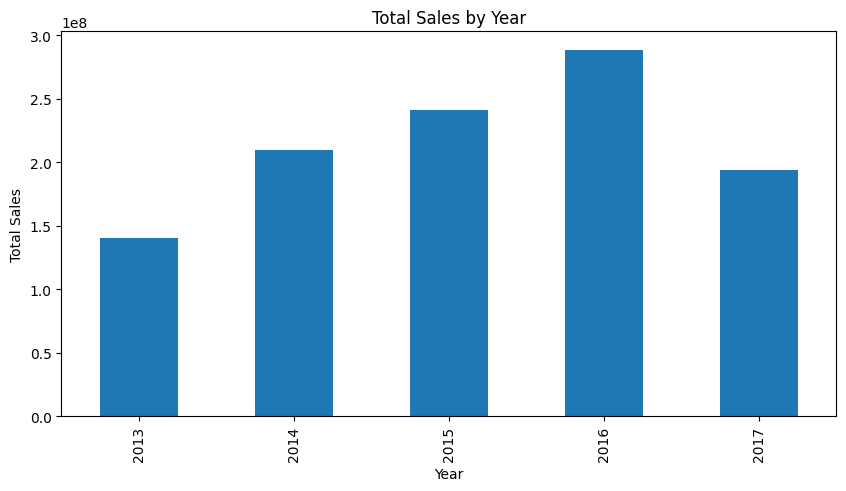

In [211]:
yearly_sales.plot(kind='bar', figsize=(10, 5))
plt.title('Total Sales by Year')
plt.xlabel('Year')
plt.ylabel('Total Sales')
plt.show()

## Preparing training and validation data

In [212]:
# Sort data chronologically
df = df.sort_values('date')

# Use the final 16 days for validation
cutoff_date = df['date'].max() - pd.Timedelta(days=15)

train_data = df[df['date'] < cutoff_date].copy()
valid_data = df[df['date'] >= cutoff_date].copy()

print("Cutoff date:", cutoff_date)
print("Training data:", train_data.shape)
print("Validation data:", valid_data.shape)

print("Training date range:",
      train_data['date'].min(), "to", train_data['date'].max())

print("Validation date range:",
      valid_data['date'].min(), "to", valid_data['date'].max())

Cutoff date: 2017-07-31 00:00:00
Training data: (2972376, 26)
Validation data: (28512, 26)
Training date range: 2013-01-01 00:00:00 to 2017-07-30 00:00:00
Validation date range: 2017-07-31 00:00:00 to 2017-08-15 00:00:00


In [213]:
target = 'sales'

X_train = train_data.drop(columns=['sales', 'date', 'id'])
y_train = train_data[target]

X_valid = valid_data.drop(columns=['sales', 'date', 'id'])
y_valid = valid_data[target]

print("X_train:", X_train.shape)
print("X_valid:", X_valid.shape)

X_train: (2972376, 23)
X_valid: (28512, 23)


In [215]:
categorical_cols = X_train.select_dtypes(
    include=['object']
).columns.tolist()

encoder = OrdinalEncoder(
    handle_unknown='use_encoded_value',
    unknown_value=-1
)

X_train[categorical_cols] = encoder.fit_transform(
    X_train[categorical_cols].astype(str)
)

X_valid[categorical_cols] = encoder.transform(
    X_valid[categorical_cols].astype(str)
)

print("Categorical columns:", categorical_cols)
print("Training shape:", X_train.shape)

Categorical columns: ['family', 'city', 'state', 'type']
Training shape: (2972376, 23)


## Model training

### 1.Random Forest

In [216]:
from sklearn.ensemble import RandomForestRegressor

# Use a sample for faster training
sample_size = min(200000, len(X_train))

X_sample = X_train.sample(
    n=sample_size,
    random_state=42
)

y_sample = y_train.loc[X_sample.index]

model = RandomForestRegressor(
    n_estimators=50,
    max_depth=15,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

model.fit(X_sample, y_sample)

print("Model training completed!")

Model training completed!


In [217]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

predictions = model.predict(X_valid)

mae = mean_absolute_error(y_valid, predictions)
rmse = np.sqrt(mean_squared_error(y_valid, predictions))

print("MAE:", mae)
print("RMSE:", rmse)

MAE: 109.27813712731792
RMSE: 374.77671199920815


### Hist Gradient Boosting

In [222]:
from sklearn.ensemble import HistGradientBoostingRegressor

In [223]:
hist_model = HistGradientBoostingRegressor(
    max_iter=150,
    learning_rate=0.1,
    max_leaf_nodes=31,
    l2_regularization=1.0,
    random_state=42
)

hist_model.fit(X_sample, y_sample)

print("HistGradientBoosting training completed!")

HistGradientBoosting training completed!


In [224]:
hist_predictions = hist_model.predict(X_valid)

hist_mae = mean_absolute_error(y_valid, hist_predictions)

hist_rmse = np.sqrt(
    mean_squared_error(y_valid, hist_predictions)
)

print("HistGradientBoosting MAE:", hist_mae)
print("HistGradientBoosting RMSE:", hist_rmse)

HistGradientBoosting MAE: 134.14044716014973
HistGradientBoosting RMSE: 333.9253566684795


In [225]:
comparison = pd.DataFrame({
    'Model': ['Random Forest', 'HistGradientBoosting'],
    'MAE': [109.2781, hist_mae],
    'RMSE': [374.7767, hist_rmse]
})

display(comparison)

,Model,MAE,RMSE
0,Random Forest,109.278100,374.776700
1,HistGradientBoosting,134.140447,333.925357


In [226]:
from sklearn.metrics import r2_score

rf_r2 = r2_score(y_valid, model.predict(X_valid))

hist_r2 = r2_score(y_valid, hist_model.predict(X_valid))

print("Random Forest R2:", rf_r2)
print("HistGradientBoosting R2:", hist_r2)

Random Forest R2: 0.9098720041499933
HistGradientBoosting R2: 0.9284493938166298


In [227]:
print("Training features:", len(X_train.columns))
print("Test columns:", len(test.columns))

print("Missing values in test:")
print(test.isnull().sum().sum())

Training features: 23
Test columns: 25
Missing values in test:
0


In [228]:
# Keep the same features used during training
X_test = test.drop(columns=['sales', 'date', 'id'], errors='ignore').copy()

# Apply the same encoder used during training
X_test[categorical_cols] = encoder.transform(
    X_test[categorical_cols].astype(str)
)

# Match the training feature order
X_test = X_test[X_train.columns]

print("X_test shape:", X_test.shape)
print("X_train shape:", X_train.shape)
print("Missing values:", X_test.isnull().sum().sum())

X_test shape: (28512, 23)
X_train shape: (2972376, 23)
Missing values: 0


In [229]:
# Random Forest predictions
rf_test_predictions = model.predict(X_test)

# HistGradientBoosting predictions
hist_test_predictions = hist_model.predict(X_test)

print("Random Forest predictions:", len(rf_test_predictions))
print("HistGradientBoosting predictions:", len(hist_test_predictions))

Random Forest predictions: 28512
HistGradientBoosting predictions: 28512


In [230]:
print("Random Forest prediction summary:")
print(pd.Series(rf_test_predictions).describe())

print("\nHistGradientBoosting prediction summary:")
print(pd.Series(hist_test_predictions).describe())

Random Forest prediction summary:
count    28512.000000
mean       479.272427
std       1245.302108
min          0.000000
25%          4.762214
50%         38.041959
75%        274.319506
max      14329.967799
dtype: float64

HistGradientBoosting prediction summary:
count    28512.000000
mean       463.574502
std       1217.501138
min       -367.721493
25%          7.477453
50%         66.812420
75%        282.544787
max      15339.278592
dtype: float64


In [232]:
import numpy as np

hist_test_predictions = np.maximum(hist_test_predictions, 0)
rf_test_predictions = np.maximum(rf_test_predictions, 0)

print("Minimum RF prediction:", rf_test_predictions.min())
print("Minimum HistGradientBoosting prediction:", hist_test_predictions.min())

Minimum RF prediction: 0.0
Minimum HistGradientBoosting prediction: 0.0


In [240]:
import joblib
import os

# Create model directory if it doesn't exist
os.makedirs("models", exist_ok=True)

# Save Random Forest
joblib.dump(
    {
        "model": model,
        "encoder": encoder,
        "categorical_cols": categorical_cols,
        "feature_columns": X_train.columns.tolist()
    },
    "models/random_forest_model.pkl"
)

# Save HistGradientBoosting
joblib.dump(
    {
        "model": hist_model,
        "encoder": encoder,
        "categorical_cols": categorical_cols,
        "feature_columns": X_train.columns.tolist()
    },
    "models/hist_gradient_boosting_model.pkl"
)

print("Both models saved successfully!")

Both models saved successfully!


In [233]:
submission = pd.DataFrame({
    'id': test['id'],
    'sales': hist_test_predictions
})

display(submission.head())

print("Submission shape:", submission.shape)

,id,sales
0,3000888,0.000000
1,3000889,0.000000
2,3000890,0.000000
3,3000891,2241.854081
4,3000892,29.024676


Submission shape: (28512, 2)


In [234]:
import os

print("Current directory:", os.getcwd())
print("Available folders:", os.listdir())

Current directory: C:\Users\Laveena\OneDrive\Desktop\Retail_Demand_Forecasting
Available folders: ['.ipynb_checkpoints', '01_Data_Understanding.ipynb', 'app', 'data', 'docker', 'mlflow', 'models', 'notebooks', 'README.md.txt']


In [235]:
submission.to_csv(
    "submission_histgradientboosting.csv",
    index=False
)

print("Submission saved successfully!")

Submission saved successfully!


In [236]:
sample_submission = pd.read_csv(
    "data/sample_submission.csv"
)

print("Sample submission:")
display(sample_submission.head())

print("Our submission:")
display(submission.head())

print("Same IDs:",
      submission['id'].equals(sample_submission['id']))

Sample submission:


,id,sales
0,3000888,0.0
1,3000889,0.0
2,3000890,0.0
3,3000891,0.0
4,3000892,0.0


Our submission:


,id,sales
0,3000888,0.000000
1,3000889,0.000000
2,3000890,0.000000
3,3000891,2241.854081
4,3000892,29.024676


Same IDs: True


In [237]:
saved_submission = pd.read_csv(
    "submission_histgradientboosting.csv"
)

print(saved_submission.shape)
print(saved_submission.isnull().sum())
print(saved_submission['sales'].describe())

(28512, 2)
id       0
sales    0
dtype: int64
count    28512.000000
mean       468.755255
std       1215.357647
min          0.000000
25%          7.477453
50%         66.812420
75%        282.544787
max      15339.278592
Name: sales, dtype: float64


In [238]:
sample_submission = pd.read_csv("data/sample_submission.csv")

print(
    "IDs match:",
    submission['id'].equals(sample_submission['id'])
)

IDs match: True


In [241]:
import os

print("DATA FOLDER:")
print(os.listdir("data"))

print("\nMODELS FOLDER:")
print(os.listdir("models"))

print("\nAPP FOLDER:")
print(os.listdir("app"))

DATA FOLDER:
['holidays_events.csv', 'oil.csv', 'sample_submission.csv', 'stores.csv', 'test.csv', 'train.csv', 'transactions.csv']

MODELS FOLDER:
['hist_gradient_boosting_model.pkl', 'random_forest_model.pkl']

APP FOLDER:
[]


## Dashboard Creation

In [242]:

import streamlit as st
import pandas as pd
import plotly.express as px
import joblib
from pathlib import Path

# -----------------------------
# PAGE CONFIGURATION
# -----------------------------
st.set_page_config(
    page_title="Retail Demand Forecasting",
    page_icon="🛒",
    layout="wide"
)

BASE_DIR = Path(__file__).resolve().parent.parent

# -----------------------------
# LOAD DATA
# -----------------------------
@st.cache_data
def load_data():
    df = pd.read_csv(BASE_DIR / "data" / "train.csv")
    stores = pd.read_csv(BASE_DIR / "data" / "stores.csv")
    df["date"] = pd.to_datetime(df["date"])
    df = df.merge(stores, on="store_nbr", how="left")
    return df

df = load_data()

# -----------------------------
# LOAD MODELS
# -----------------------------
@st.cache_resource
def load_models():
    rf = joblib.load(
        BASE_DIR / "models" / "random_forest_model.pkl"
    )
    hist = joblib.load(
        BASE_DIR / "models" / "hist_gradient_boosting_model.pkl"
    )
    return rf, hist

rf_bundle, hist_bundle = load_models()

# -----------------------------
# SIDEBAR
# -----------------------------
st.sidebar.title("Retail Analytics")
page = st.sidebar.radio(
    "Navigate",
    ["Overview", "Sales Analysis", "Store Analysis",
     "Product Analysis", "Model Comparison", "Forecasting"]
)

st.title("🛒 Retail Demand Forecasting & Analytics")
st.caption("Sales insights and machine learning model analysis")

# -----------------------------
# OVERVIEW
# -----------------------------
if page == "Overview":

    st.header("Business Overview")

    total_sales = df["sales"].sum()
    total_stores = df["store_nbr"].nunique()
    total_families = df["family"].nunique()

    c1, c2, c3 = st.columns(3)

    c1.metric("Total Sales", f"{total_sales:,.0f}")
    c2.metric("Total Stores", total_stores)
    c3.metric("Product Families", total_families)

    st.subheader("Daily Sales Trend")

    daily = df.groupby("date", as_index=False)["sales"].sum()

    fig = px.line(
        daily,
        x="date",
        y="sales",
        title="Daily Retail Sales"
    )

    st.plotly_chart(fig, use_container_width=True)

# -----------------------------
# SALES ANALYSIS
# -----------------------------
elif page == "Sales Analysis":

    st.header("Sales Analysis")

    monthly = (
        df.groupby(df["date"].dt.to_period("M"))["sales"]
        .sum()
        .reset_index()
    )

    monthly["date"] = monthly["date"].astype(str)

    fig = px.bar(
        monthly,
        x="date",
        y="sales",
        title="Monthly Sales"
    )

    st.plotly_chart(fig, use_container_width=True)

    yearly = df.groupby(df["date"].dt.year)["sales"].sum().reset_index()
    yearly.columns = ["Year", "Sales"]

    fig2 = px.bar(
        yearly,
        x="Year",
        y="Sales",
        title="Yearly Sales"
    )

    st.plotly_chart(fig2, use_container_width=True)

# -----------------------------
# STORE ANALYSIS
# -----------------------------
elif page == "Store Analysis":

    st.header("Store Performance")

    store_sales = (
        df.groupby(["store_nbr", "city"], as_index=False)["sales"]
        .sum()
        .sort_values("sales", ascending=False)
    )

    fig = px.bar(
        store_sales,
        x="store_nbr",
        y="sales",
        color="city",
        title="Sales by Store"
    )

    st.plotly_chart(fig, use_container_width=True)

    st.dataframe(store_sales, use_container_width=True)

# -----------------------------
# PRODUCT ANALYSIS
# -----------------------------
elif page == "Product Analysis":

    st.header("Product Family Performance")

    family_sales = (
        df.groupby("family", as_index=False)["sales"]
        .sum()
        .sort_values("sales", ascending=False)
    )

    fig = px.bar(
        family_sales.head(15),
        x="family",
        y="sales",
        title="Top 15 Product Families"
    )

    st.plotly_chart(fig, use_container_width=True)

    st.dataframe(family_sales, use_container_width=True)

# -----------------------------
# MODEL COMPARISON
# -----------------------------
elif page == "Model Comparison":

    st.header("Machine Learning Model Performance")

    comparison = pd.DataFrame({
        "Model": ["Random Forest", "HistGradientBoosting"],
        "MAE": [109.2781, 134.1404],
        "RMSE": [374.7767, 333.9254],
        "R2": [0.9099, 0.9284]
    })

    st.dataframe(comparison, use_container_width=True)

    fig = px.bar(
        comparison,
        x="Model",
        y=["MAE", "RMSE"],
        barmode="group",
        title="Model Error Comparison"
    )

    st.plotly_chart(fig, use_container_width=True)

# -----------------------------
# FORECASTING
# -----------------------------
elif page == "Forecasting":

    st.header("Test Dataset Predictions")

    predictions_path = (
        BASE_DIR / "submission_histgradientboosting.csv"
    )

    if predictions_path.exists():
        predictions = pd.read_csv(predictions_path)

        st.metric("Predicted Records", len(predictions))

        st.dataframe(predictions.head(100), use_container_width=True)

        fig = px.histogram(
            predictions,
            x="sales",
            title="Distribution of Predicted Sales"
        )

        st.plotly_chart(fig, use_container_width=True)

    else:
        st.warning("Prediction CSV not found in project folder.")

st.sidebar.success("Dashboard loaded")


2026-11-16 22:13:42.979 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


NameError: name '__file__' is not defined